# Orlando, Florida — Municipal Resilience Planning EDA

**CMSE 495 / NIST pilot | Geography: City of Orlando, Florida**

**Goal:** Collect a small, *real* set of official Orlando planning sources; extract text; assess reliability; and conduct preliminary descriptive/text analysis. This notebook does **not** claim an exhaustive document inventory or infer policy implementation from keyword counts.

Sources include official City of Orlando pages/PDFs. The geographic scope is **city government**, not all of Orange County. Candidate URLs are checked at runtime, so failed downloads remain visible rather than being silently dropped.


## 1. Setup and imports
Run this installation cell once in the notebook environment. Network access is required to download the public source documents.

In [1]:
%pip install -q pandas numpy matplotlib seaborn requests beautifulsoup4 trafilatura pymupdf scikit-learn

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
You should consider upgrading via the '/Library/Developer/CommandLineToo

In [4]:
from pathlib import Path
from urllib.parse import urlparse, urljoin, urldefrag
from collections import Counter
import hashlib, io, re, time, json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import trafilatura
import fitz  # PyMuPDF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from IPython.display import display

sns.set_theme(style="whitegrid")
DATA_DIR = Path("orlando_eda_output")
DATA_DIR.mkdir(exist_ok=True)
REQUEST_TIMEOUT = 30
MAX_BYTES = 60_000_000     # Reject abnormally large downloads in this small pilot
PAUSE_SECONDS = 0.7      # Polite gap between requests
HEADERS = {"User-Agent": "CMSE495-Orlando-EDA/0.1 (educational research; contact via project team)"}
SESSION = requests.Session()
SESSION.headers.update(HEADERS)
print("Output directory:", DATA_DIR.resolve())

Output directory: /Users/aryasharma/Downloads/orlando_eda_output


## 2. Define sources and reproducible metadata
The five initial URLs below are candidate documents/pages on the **official City of Orlando website**. A URL listed here is not a guarantee of a successful download.

In [8]:
# Orlando, Florida - Initial Source List

SOURCES = [
    {
        "title": "Orlando Resilience Plan",
        "url": "https://www.orlando.gov/Our-Government/Orlando-plans-for-a-future-ready-city/Orlando-Resilience-Plan",
        "document_type": "resilience_plan",
        "expected_format": "html",
    },
    {
        "title": "Orlando Future-Ready City",
        "url": "https://www.orlando.gov/Our-Government/Orlando-plans-for-a-future-ready-city",
        "document_type": "planning_webpage",
        "expected_format": "html",
    },
    {
        "title": "Solar in the City of Orlando",
        "url": "https://www.orlando.gov/Our-Government/Departments-Offices/Executive-Offices/CAO/Sustainability-Resilience/Initiatives/Solar-in-the-City-of-Orlando",
        "document_type": "initiative_webpage",
        "expected_format": "html",
    },
    {
        "title": "Orlando Office of Sustainability and Resilience",
        "url": "https://www.orlando.gov/Our-Government/Departments-Offices/Executive-Offices/CAO/Sustainability-Resilience",
        "document_type": "department_webpage",
        "expected_format": "html",
    },
]

# Convert source list into a DataFrame
seeds = pd.DataFrame(SOURCES)

# Add geographic metadata
seeds.insert(0, "city", "Orlando")
seeds.insert(1, "state", "Florida")

# Preview sources
display(seeds[["title", "document_type", "expected_format", "url"]])
seeds = pd.DataFrame(SOURCES)
seeds.insert(0, "city", "Orlando")
seeds.insert(1, "state", "Florida")
display(seeds[["title", "document_type", "url"]])

,title,document_type,expected_format,url
0,Orlando Resilience Plan,resilience_plan,html,https://www.orlando.gov/Our-Government/Orlando...
1,Orlando Future-Ready City,planning_webpage,html,https://www.orlando.gov/Our-Government/Orlando...
2,Solar in the City of Orlando,initiative_webpage,html,https://www.orlando.gov/Our-Government/Departm...
3,Orlando Office of Sustainability and Resilience,department_webpage,html,https://www.orlando.gov/Our-Government/Departm...


,title,document_type,url
0,Orlando Resilience Plan,resilience_plan,https://www.orlando.gov/Our-Government/Orlando...
1,Orlando Future-Ready City,planning_webpage,https://www.orlando.gov/Our-Government/Orlando...
2,Solar in the City of Orlando,initiative_webpage,https://www.orlando.gov/Our-Government/Departm...
3,Orlando Office of Sustainability and Resilience,department_webpage,https://www.orlando.gov/Our-Government/Departm...


## 3. Fetch official URLs safely and record failures
Limit transfer sizes; report HTTP status and redirects. Do not scrape large portions of the site or bypass access restrictions.

In [9]:
def fetch_limited(url):
    result = {"status": "error", "http_status": None, "final_url": None,
              "content_type": None, "byte_size": 0, "error": None, "body": b""}
    try:
        with SESSION.get(url, timeout=REQUEST_TIMEOUT, allow_redirects=True, stream=True) as r:
            result["http_status"] = r.status_code
            result["final_url"] = r.url
            result["content_type"] = r.headers.get("Content-Type", "").split(";")[0].lower()
            r.raise_for_status()
            chunks, total = [], 0
            for chunk in r.iter_content(chunk_size=65536):
                if not chunk:
                    continue
                total += len(chunk)
                if total > MAX_BYTES:
                    raise ValueError(f"Exceeded {MAX_BYTES:,}-byte pilot download limit")
                chunks.append(chunk)
            result.update(status="ok", byte_size=total, body=b"".join(chunks))
    except Exception as e:
        result["error"] = f"{type(e).__name__}: {e}"
    return result

raw_results = []
for row in SOURCES:
    response = fetch_limited(row["url"])
    raw_results.append({**row, **response, "retrieved_at_utc": datetime.now(timezone.utc).isoformat()})
    print(row["title"], "->", response["status"], response["http_status"], response["byte_size"], "bytes")
    time.sleep(PAUSE_SECONDS)

fetch_report = pd.DataFrame([{k: v for k, v in r.items() if k != "body"} for r in raw_results])
display(fetch_report[["title", "status", "http_status", "content_type", "byte_size", "error"]])

Orlando Resilience Plan -> ok 200 185645 bytes
Orlando Future-Ready City -> ok 200 193441 bytes
Solar in the City of Orlando -> ok 200 192133 bytes
Orlando Office of Sustainability and Resilience -> ok 200 189639 bytes


,title,status,http_status,content_type,byte_size,error
0,Orlando Resilience Plan,ok,200,text/html,185645,None
1,Orlando Future-Ready City,ok,200,text/html,193441,None
2,Solar in the City of Orlando,ok,200,text/html,192133,None
3,Orlando Office of Sustainability and Resilience,ok,200,text/html,189639,None


## 4. Extract HTML/PDF text
A short or empty PDF extraction may indicate image scans, an access problem, or a PDF that needs manual review. **OCR is not attempted automatically.**

In [10]:
def clean_text(text):
    text = (text or "").replace("\x00", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n\s*\n+", "\n\n", text)
    return text.strip()

def extract_document(item):
    out = {k: v for k, v in item.items() if k != "body"}
    out.update(text="", format="unknown", extraction_method="none", page_count=np.nan, extraction_error=None)
    if item["status"] != "ok":
        return out
    content = item["body"]
    ctype = item.get("content_type") or ""
    is_pdf = content.startswith(b"%PDF") or "pdf" in ctype or urlparse(item["final_url"] or item["url"]).path.lower().endswith(".pdf")
    try:
        if is_pdf:
            with fitz.open(stream=content, filetype="pdf") as pdf:
                out["page_count"] = len(pdf)
                text = "\n".join(page.get_text("text") for page in pdf)
            out["format"] = "PDF"
            out["extraction_method"] = "PyMuPDF"
        elif "html" in ctype or content.lstrip()[:100].lower().startswith((b"<!doctype", b"<html")):
            html = content.decode("utf-8", errors="replace")
            text = trafilatura.extract(html, include_comments=False, include_tables=True) or ""
            if not text.strip():
                soup = BeautifulSoup(html, "html.parser")
                for tag in soup(["script", "style", "nav", "footer", "header"]):
                    tag.decompose()
                text = soup.get_text(" ", strip=True)
                out["extraction_method"] = "BeautifulSoup fallback"
            else:
                out["extraction_method"] = "trafilatura"
            out["format"] = "HTML"
        else:
            raise ValueError(f"Unsupported content type: {ctype!r}")
        out["text"] = clean_text(text)
    except Exception as e:
        out["extraction_error"] = f"{type(e).__name__}: {e}"
    return out

docs = pd.DataFrame([extract_document(r) for r in raw_results])
docs["char_count"] = docs["text"].str.len()
docs["word_count"] = docs["text"].str.findall(r"\b[\w'-]+\b").str.len()
docs["needs_review"] = (docs["status"] != "ok") | (docs["word_count"] < 100) | docs["extraction_error"].notna()
display(docs[["title", "format", "page_count", "word_count", "extraction_method", "needs_review", "extraction_error"]])

,title,format,page_count,word_count,extraction_method,needs_review,extraction_error
0,Orlando Resilience Plan,HTML,NaN,511,trafilatura,False,None
1,Orlando Future-Ready City,HTML,NaN,721,trafilatura,False,None
2,Solar in the City of Orlando,HTML,NaN,1688,trafilatura,False,None
3,Orlando Office of Sustainability and Resilience,HTML,NaN,418,trafilatura,False,None


## 5. Preview and manually validate extraction quality
Do the previews look like actual Orlando planning content? Watch for navigation, PDF headers/footers, scrambled text, and cross-referenced plans.

In [11]:
for _, row in docs.iterrows():
    print("\n" + "=" * 80)
    print(row["title"], "|", row["status"], "|", row["word_count"], "words")
    print((row["text"] or "")[:650] or "[NO TEXT EXTRACTED]")

display(docs.loc[docs["needs_review"], ["title", "status", "http_status", "word_count", "error", "extraction_error"]])


Orlando Resilience Plan | ok | 511 words
The City of Orlando is working to develop a Resilience Plan to solve some of our toughest challenges and strengthen our ability to overcome the potential impacts of natural disasters or manmade threats. This includes hurricanes and extreme heat; homelessness; affordable housing; access to free internet for all, and more. The Resilience Plan will provide the Orlando community and city staff with a framework of policies, programs, and other actions to improve the city’s resilience to hazards, changing conditions, and socioeconomic stresses. Strategies will be evaluated to create a more equitable city and ensure that all persons have the resourc

Orlando Future-Ready City | ok | 721 words
"In Orlando, our goal is to become America's premier future-ready city." - Buddy Dyer, Mayor
In Orlando, our goal is to become America’s premier Future-Ready City. While we cannot predict exactly what the future holds, having a well-planned, collaborative vision 

,title,status,http_status,word_count,error,extraction_error


## 6. Clean analysis corpus, detect exact duplicates
The HTML landing page and corresponding PDF may discuss the same plan without being identical. Exact hashes identify only *exact extracted-text duplicates*; they do not establish semantic similarity.

In [12]:
analysis_df = docs.loc[(docs["status"] == "ok") & (docs["word_count"] >= 100)].copy()
analysis_df["normalized_text"] = analysis_df["text"].map(lambda s: re.sub(r"\s+", " ", s).strip().lower())
analysis_df["sha256_text"] = analysis_df["normalized_text"].map(lambda s: hashlib.sha256(s.encode()).hexdigest())
analysis_df["exact_duplicate"] = analysis_df.duplicated("sha256_text", keep="first")
analysis_df["word_count"] = analysis_df["text"].str.findall(r"\b[\w'-]+\b").str.len()
analysis_unique = analysis_df.loc[~analysis_df["exact_duplicate"]].copy().reset_index(drop=True)
print("Seed URLs:", len(docs))
print("Successful downloads:", (docs["status"] == "ok").sum())
print("Usable extracted texts (>=100 words):", len(analysis_df))
print("Exact text duplicates:", int(analysis_df["exact_duplicate"].sum()))
print("Unique analysis records:", len(analysis_unique))
display(analysis_df[["title", "document_type", "format", "word_count", "exact_duplicate"]])

Seed URLs: 4
Successful downloads: 4
Usable extracted texts (>=100 words): 4
Exact text duplicates: 0
Unique analysis records: 4


,title,document_type,format,word_count,exact_duplicate
0,Orlando Resilience Plan,resilience_plan,HTML,511,False
1,Orlando Future-Ready City,planning_webpage,HTML,721,False
2,Solar in the City of Orlando,initiative_webpage,HTML,1688,False
3,Orlando Office of Sustainability and Resilience,department_webpage,HTML,418,False


## 7. EDA — Retrieval and document characteristics

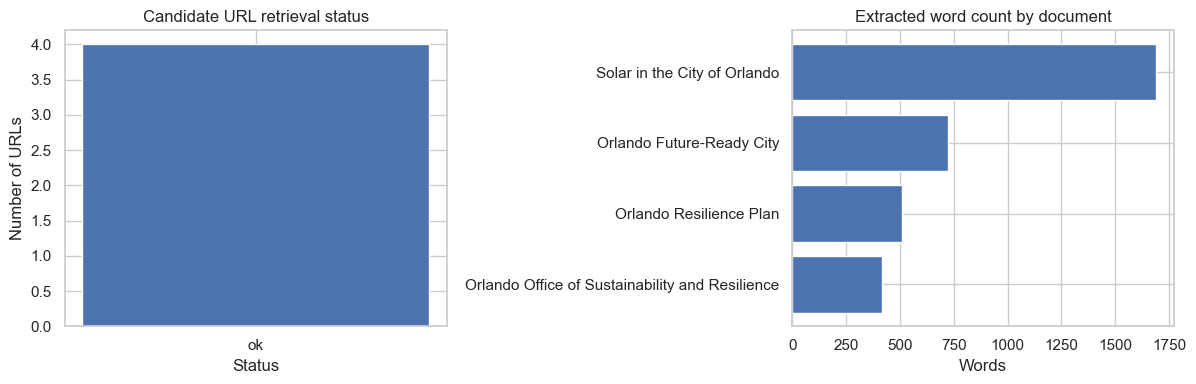

,document_type,format,documents,total_words,mean_words
0,department_webpage,HTML,1,418,418.0
1,initiative_webpage,HTML,1,1688,1688.0
2,planning_webpage,HTML,1,721,721.0
3,resilience_plan,HTML,1,511,511.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
status_counts = docs["status"].value_counts()
axes[0].bar(status_counts.index.astype(str), status_counts.values)
axes[0].set(title="Candidate URL retrieval status", xlabel="Status", ylabel="Number of URLs")
if not analysis_unique.empty:
    plot_df = analysis_unique.sort_values("word_count")
    axes[1].barh(plot_df["title"], plot_df["word_count"])
    axes[1].set(title="Extracted word count by document", xlabel="Words")
else:
    axes[1].text(0.5, 0.5, "No usable text retrieved", ha="center", va="center", transform=axes[1].transAxes)
plt.tight_layout()
plt.show()

if not analysis_unique.empty:
    display(analysis_unique.groupby(["document_type", "format"], dropna=False).agg(
        documents=("title", "count"), total_words=("word_count", "sum"),
        mean_words=("word_count", "mean")).reset_index())

## 8. Preliminary theme analysis (descriptive keyword presence)
These are **exploratory dictionaries**, not validated labels, and word/phrase mentions do not imply commitment or implementation. Count each theme in each document using case-insensitive whole-word/phrase matching.

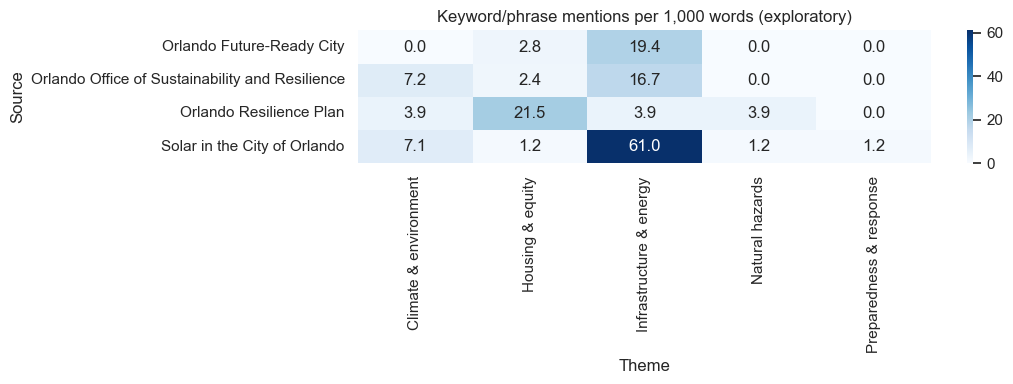

,theme,mentions
2,Infrastructure & energy,126
0,Climate & environment,17
1,Housing & equity,16
3,Natural hazards,4
4,Preparedness & response,2


In [14]:
THEMES = {
    "Natural hazards": ["hurricane", "hurricanes", "flood", "flooding", "storm", "storms", "disaster", "extreme heat"],
    "Climate & environment": ["climate", "adaptation", "sustainability", "emissions", "greenhouse gas", "heat island"],
    "Infrastructure & energy": ["infrastructure", "electricity", "energy", "power", "grid", "solar", "water", "transportation"],
    "Housing & equity": ["housing", "affordable housing", "equity", "equitable", "vulnerable", "low-income", "homelessness"],
    "Preparedness & response": ["preparedness", "emergency", "response", "recovery", "mitigation", "resilience hub"],
}

def count_phrases(text, phrases):
    text = (text or "").lower()
    return sum(len(re.findall(r"(?<!\w)" + re.escape(phrase.lower()) + r"(?!\w)", text)) for phrase in phrases)

theme_rows = []
for _, row in analysis_unique.iterrows():
    for theme, phrases in THEMES.items():
        mentions = count_phrases(row["text"], phrases)
        theme_rows.append({"title": row["title"], "theme": theme, "mentions": mentions,
                           "per_1000_words": mentions / row["word_count"] * 1000 if row["word_count"] else 0})
theme_df = pd.DataFrame(theme_rows, columns=["title", "theme", "mentions", "per_1000_words"])
if not theme_df.empty:
    matrix = theme_df.pivot(index="title", columns="theme", values="per_1000_words").fillna(0)
    plt.figure(figsize=(11, max(4, len(matrix) * 0.75)))
    sns.heatmap(matrix, annot=True, fmt=".1f", cmap="Blues")
    plt.title("Keyword/phrase mentions per 1,000 words (exploratory)")
    plt.xlabel("Theme")
    plt.ylabel("Source")
    plt.tight_layout()
    plt.show()
    display(theme_df.groupby("theme", as_index=False)["mentions"].sum().sort_values("mentions", ascending=False))
else:
    print("No texts to score; inspect failed downloads above.")

## 9. Most frequent meaningful terms
This is an unweighted aggregate across documents: longer PDFs will contribute more total terms. The document comparison above is normalized per 1,000 words.

,term,count
235,energy,54
719,solar,50
648,renewable,17
554,plan,17
119,community,16
658,resilience,16
657,residents,16
301,future,13
742,strategies,12
378,includes,12


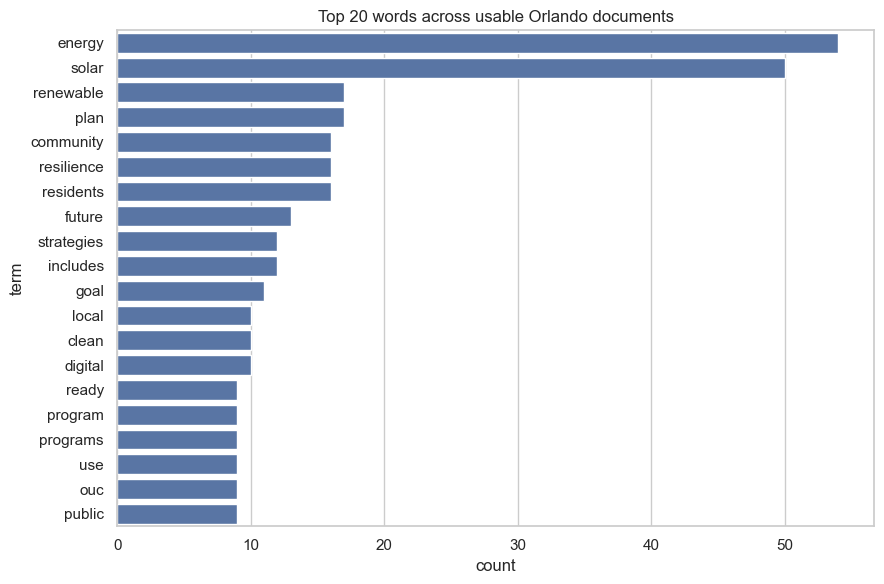

In [15]:
CUSTOM_STOP = set(ENGLISH_STOP_WORDS) | {"orlando", "city", "florida", "page", "www", "http", "https", "gov", "2020", "2018"}
corpus = analysis_unique["text"].tolist()
if corpus:
    cv = CountVectorizer(stop_words=list(CUSTOM_STOP), min_df=1, max_features=2000,
                         token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]{2,}\b")
    X_counts = cv.fit_transform(corpus)
    term_counts = np.asarray(X_counts.sum(axis=0)).ravel()
    frequent = pd.DataFrame({"term": cv.get_feature_names_out(), "count": term_counts})
    frequent = frequent.sort_values("count", ascending=False).head(20)
    display(frequent)
    plt.figure(figsize=(9, 6))
    sns.barplot(data=frequent, y="term", x="count")
    plt.title("Top 20 words across usable Orlando documents")
    plt.tight_layout()
    plt.show()
else:
    frequent = pd.DataFrame(columns=["term", "count"])
    print("No usable documents for word frequencies.")

## 10. Preliminary TF-IDF by document
TF-IDF highlights distinguishing vocabulary within this tiny, curated corpus. With only a few sources, treat the rankings as exploratory rather than statistically robust.

In [16]:
tfidf_rows = []
if len(corpus) >= 2:
    vectorizer = TfidfVectorizer(stop_words=list(CUSTOM_STOP), max_features=3000,
                                 token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]{2,}\b", sublinear_tf=True)
    X = vectorizer.fit_transform(corpus)
    terms = np.array(vectorizer.get_feature_names_out())
    for i, title in enumerate(analysis_unique["title"]):
        scores = X[i].toarray().ravel()
        for j in np.argsort(scores)[-10:][::-1]:
            if scores[j] > 0:
                tfidf_rows.append({"title": title, "term": terms[j], "tfidf": float(scores[j])})
    tfidf_df = pd.DataFrame(tfidf_rows)
    display(tfidf_df)
else:
    tfidf_df = pd.DataFrame(columns=["title", "term", "tfidf"])
    print("TF-IDF comparison requires at least two usable documents.")

,title,term,tfidf
0,Orlando Resilience Plan,resilience,0.183815
1,Orlando Resilience Plan,assessment,0.163736
2,Orlando Resilience Plan,plan,0.148814
3,Orlando Resilience Plan,vulnerability,0.143996
4,Orlando Resilience Plan,include,0.143996
5,Orlando Resilience Plan,thoughts,0.143996
6,Orlando Resilience Plan,planning,0.143996
7,Orlando Resilience Plan,staff,0.143996
8,Orlando Resilience Plan,workshops,0.129091
9,Orlando Resilience Plan,adversity,0.116175


## 11. Retrieve context around resilience terms
Keyword counts alone can mislead. Read short passages to determine whether mentions describe hazards, proposed actions, past accomplishments, or unrelated boilerplate.

In [17]:
def context_snippets(text, term="resilience", max_snippets=3, window=130):
    matches = list(re.finditer(re.escape(term), text or "", flags=re.IGNORECASE))
    return [re.sub(r"\s+", " ", text[max(0, m.start()-window):m.end()+window]).strip()
            for m in matches[:max_snippets]]

for _, row in analysis_unique.iterrows():
    print("\n###", row["title"])
    snippets = context_snippets(row["text"], term="resilien", max_snippets=3)
    # 'resilien' catches resilience, resilient, and resiliency
    if snippets:
        for snippet in snippets:
            print(" •", snippet)
    else:
        print("No occurrences of 'resilien' found.")


### Orlando Resilience Plan
 • The City of Orlando is working to develop a Resilience Plan to solve some of our toughest challenges and strengthen our ability to overcome the potential impacts of natural disasters
 • eats. This includes hurricanes and extreme heat; homelessness; affordable housing; access to free internet for all, and more. The Resilience Plan will provide the Orlando community and city staff with a framework of policies, programs, and other actions to improve the
 • will provide the Orlando community and city staff with a framework of policies, programs, and other actions to improve the city’s resilience to hazards, changing conditions, and socioeconomic stresses. Strategies will be evaluated to create a more equitable city and e

### Orlando Future-Ready City
 • tegies for water re-use, conservation and monitoring. Energy pillar is aligned with these initiatives and includes strategies for resilient, reliable and affordable energy for all. Health & Safety Protecting

## 12. Export auditable data products and document pilot limitations

In [18]:
# Save text and metadata separately so the metadata CSV remains easy to inspect.
metadata_cols = ["title", "document_type", "source_scope", "url", "final_url", "status", "http_status",
                 "content_type", "format", "byte_size", "page_count", "word_count", "char_count",
                 "extraction_method", "needs_review", "extraction_error", "error", "retrieved_at_utc"]
for col in metadata_cols:
    if col not in docs:
        docs[col] = pd.NA
docs[metadata_cols].to_csv(DATA_DIR / "orlando_source_audit.csv", index=False)
analysis_unique.drop(columns=["normalized_text"], errors="ignore").to_json(
    DATA_DIR / "orlando_extracted_documents.json", orient="records", indent=2, force_ascii=False)
theme_df.to_csv(DATA_DIR / "orlando_theme_counts.csv", index=False)
tfidf_df.to_csv(DATA_DIR / "orlando_tfidf_top_terms.csv", index=False)

summary = {
    "city": "Orlando", "state": "Florida", "geographic_scope": "City of Orlando",
    "seed_url_count": len(docs), "downloads_succeeded": int((docs["status"] == "ok").sum()),
    "usable_unique_documents": len(analysis_unique),
    "extraction_needs_review": docs.loc[docs["needs_review"], "title"].tolist(),
    "limitations": [
        "Small manually seeded corpus; not exhaustive or representative of all Orlando plans",
        "A webpage and its PDF may describe the same plan even if their text hashes differ",
        "No manual ground-truth relevance annotation yet",
        "No OCR for scanned/image-only PDFs",
        "Keyword matches do not prove policy commitments or implementations",
        "Publication date is not inferred from a URL or HTTP retrieval date"
    ]
}
(DATA_DIR / "pilot_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print("\nSaved:")
for path in DATA_DIR.iterdir():
    print("-", path)

{
  "city": "Orlando",
  "state": "Florida",
  "geographic_scope": "City of Orlando",
  "seed_url_count": 4,
  "downloads_succeeded": 4,
  "usable_unique_documents": 4,
  "extraction_needs_review": [],
  "limitations": [
    "Small manually seeded corpus; not exhaustive or representative of all Orlando plans",
    "A webpage and its PDF may describe the same plan even if their text hashes differ",
    "No manual ground-truth relevance annotation yet",
    "No OCR for scanned/image-only PDFs",
    "Keyword matches do not prove policy commitments or implementations",
    "Publication date is not inferred from a URL or HTTP retrieval date"
  ]
}

Saved:
- orlando_eda_output/pilot_summary.json
- orlando_eda_output/orlando_extracted_documents.json
- orlando_eda_output/orlando_source_audit.csv
- orlando_eda_output/orlando_theme_counts.csv
- orlando_eda_output/orlando_tfidf_top_terms.csv


## 13. Interpretation prompts for your report

After running all cells, summarize **observed outputs** (not assumed findings):

1. How many of the candidate URLs succeeded, and which failed or redirected?
2. Were both HTML and PDF content extracted correctly? Which sources require manual repair/OCR?
3. Which themes appeared in which sources? Were they concentrated in any one document?
4. What words distinguished the resilience page from the sustainability/energy documents? Does manual inspection support these differences?
5. Which critical document types remain missing (e.g., hazard mitigation, emergency management, broader comprehensive planning)?

**Next-stage plan:** Validate candidate relevance with the partner; add official-source keyword/sitemap discovery or UScityURL-based search; collect publication dates from verified plan metadata; expand to county plans with a separate jurisdiction field; add near-duplicate detection, OCR selectively, and document-level labels.

**Source provenance:** Official City of Orlando URLs are explicitly recorded in the `url` / `final_url` fields. The UScityURL repository is useful for scaling to additional municipalities: https://github.com/caimeng2/UScityURL .
